## Read the train/test data

In [1]:
import collections

import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/alleles_with_groups/"
# TARGET_LENGTHS = [9, 10]
TARGET_LENGTHS = [13, 14, 15, 16, 17, 18]

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))
ALLELES = [   'HLA-DRB1*01:01'

    # 'HLA-A*01:01',
           # 'HLA-A*03:01',
           # 'HLA-A*02:01' 
          ]

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
          
# ALLELES = ['HLA-A*01:01', 'HLA-A*03:01']
ALLELES

['HLA-DRB1*01:01']

In [4]:
per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9]

array(['SLVNLGGSK', 'GDYEGLWGL', 'PGAKAKSLE', 'GRVFIIKSY', 'TDYISKVKE',
       'AVFTDNYTR', 'WAVVAAFTK', 'KIFEFKETL', 'LGRGLLGLI', 'AAKGTQVVK',
       'KRLASSVLR', 'PAKSAPAPK', 'QIIQEKRGY', 'LLADQAEAR', 'YTALAAPAL',
       'YKTLRAEQA', 'DGALTGGMC', 'LRDEGLRLR', 'KRYKSIVKY', 'EKDYEILFK',
       'HHDEEKDVI', 'GRVAPRSGL', 'LVPHLHERR', 'ADAAPDEKV', 'RLGVDLAEV',
       'KQVHPDTGI', 'AVTAMKSRP', 'RRFGDKLNF', 'QRIISLSVD', 'KRFEGLTQR',
       'YVTTSTRTY', 'FVKQNAAAA', 'WFVNNVEVH', 'EEFGRFASF', 'YAALATAAL',
       'GTGASGSFK', 'AASSSSLEK', 'GRVHRLLRK', 'PLKVYPPLK', 'MFRRLTFAQ',
       'HRAQVIYTR', 'EDDQRPVCL', 'NAGAVLNFK', 'RTEEREQIK', 'TGHGKYEKV',
       'HPDTGISSK', 'ELNKEVSTN', 'VETRDGQVI', 'RVYIHPFHL', 'IKTQEKAPV',
       'RVGIVSNDP', 'VENKIVSLD', 'KRFSGTVRL', 'YHQYAYDGK', 'VASFPKKQE',
       'AKVINISVT', 'KSAELNKEV', 'LNQSHRTLK', 'SDEAERDEY', 'WYNRCHAAN',
       'FQVLKSLGK', 'MNEKLKKFF', 'RRYQKSTEL', 'LLSTRDLAF', 'KETIEQEKQ',
       'VHFFKNIVT', 'KEKYEKDIA', 'LSLMLVSTV', 'LFTRKNPYR', 'TPEQ

## Also add immunogenic data

In [5]:
from os import listdir
from os.path import isfile, join
from mhcnames import normalize_allele_name
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/' # windows

onlyfiles = [f for f in listdir(DATA_PATH) if isfile(join(DATA_PATH, f))]
IMM_ALLELES = []
per_allele_imm_df = dict()
for file_name in onlyfiles:
    allele_name = file_name.split("_", 1)[1].split('.')[0]
    allele_name = normalize_allele_name(allele_name)
    per_allele_imm_df[allele_name] =  pd.read_csv(DATA_PATH + file_name,sep=";")
    IMM_ALLELES.append(allele_name)
IMM_ALLELES

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']

In [6]:
IMM_ALLELES

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']

In [7]:
from data_reading_methods import get_available_alleles, read_data
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows

def merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders, per_allele_imm_data):
    for allele in ALLELES:
        if allele in IMM_ALLELES:
            new_allele = allele + "_imm"
            
            per_allele_per_kfold_per_length_binders[new_allele] = dict()
            # per_length_peptides = defaultdict(list)
            
            # for kfold, per_length_imm_peptides in per_allele_per_kfold_per_length_imm[allele].items():
            #     for target_length, peptides in per_length_imm_peptides.items():
            #         per_length_peptides[target_length].extend(peptides)
            for kfold, per_length_peptides in per_allele_per_kfold_per_length_binders[allele].items():
                per_allele_per_kfold_per_length_binders[new_allele][kfold] = dict()
                for target_length in per_length_peptides.keys():
                    imm_df = per_allele_imm_data[allele]
                    imm_df = imm_df[imm_df['immunogenic'] == 1]
                    imm_df = imm_df[imm_df['length'] == target_length]
                    per_allele_per_kfold_per_length_binders[new_allele][kfold][target_length] = imm_df['peptide'].values
                    
merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_train, per_allele_imm_df)
merge_imm_data_to_binders_data_as_new_alleles(per_allele_per_kfold_per_length_binders_test, per_allele_imm_df)


In [8]:
per_allele_per_kfold_per_length_binders_test.keys()

dict_keys(['HLA-DRB1*01:01'])

# Read models

In [14]:
# MODELS PARAMS
## PARAMETERS
RUNS = 2
# RUNS = 5
total_splits = 1
SELECTED_RUN = 0
SELECTED_RUN = {0,1,2,3,4,5,
                6, 7, 8, 9
               }
SELECTED_RUN = {0,1
                }

SELECTED_SPLIT = 0

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": [
            #'HLA-A*01:01', 
            'HLA-A*03:01', 
            #'HLA-A*02:01'
        ],
        "target_lengths": [9, 10]
    },
        "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
            "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 35,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
        "single_allele_balanced_class2_joiners": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [15]:
selected_models = [
                 #'single_allele_imbalanced', 
                #'multiple_allele_imbalanced',
                  # 'single_allele_balanced',
                     # 'multiple_allele_balanced',
                # 'single_allele_balanced_class2',
    # 'single_allele_balanced_class2_biger' 
    'single_allele_balanced_class2_joiners'
]

In [16]:
from hmm_logic_methods import load_model

In [17]:
import itertools


target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
max_target_length = max(TARGET_LENGTHS)
total_splits = 1


name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_general_type = dict()
name_to_model_root = dict()
selected_binding_models = list()
per_name_binding_model = dict()
name_to_target_lengths = dict()
name_to_acceptable_alleles = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, model_general_type, acceptable_alleles):
    # print(model_name)
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv"]
    name_to_type[model_name] = model_type
    name_to_general_type[model_name] = model_general_type
    name_to_acceptable_alleles[model_name] = acceptable_alleles

    
    
for model_general_type in selected_models:
    print(model_general_type)
    model_description = MODELS_DESCRIPTIONS[model_general_type]
    combination_size = model_description['combination_size']
    model_class_alleles = model_description['alleles'] # just alleles used in all training process (the actual value could be less alleles)
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()
    for combination in itertools.combinations(sorted(model_class_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)
    for allele_name in MIXED_ALLELES:
        model_alleles = allele_name.split("+")
        
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(total_splits):
                #bw
                bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, "bw", model_general_type, model_alleles)
                #bwv
                bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, "bwv", model_general_type, model_alleles)
                #v
                v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, "v", model_general_type, model_alleles)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)    
    

single_allele_balanced_class2_joiners


In [18]:
list(per_name_binding_model.keys())

['0_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '0_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi',
 '0_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi',
 '1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0']

## Select run and split

In [19]:
for model_key in list(per_name_binding_model.keys()):
    if name_to_split[model_key] != SELECTED_SPLIT:
        del per_name_binding_model[model_key]
    elif type(SELECTED_RUN) == set:
        if name_to_run[model_key] not in SELECTED_RUN:
            del per_name_binding_model[model_key] 
    elif name_to_run[model_key] != SELECTED_RUN:
        del per_name_binding_model[model_key] 
per_name_binding_model = dict(reversed(sorted(per_name_binding_model.items(), key=lambda item: item[0])))

# Populate path embeddings for all models
Here we have already read our models and train/test data.
Now we want to extract representaion of our data for selected models. 



In [20]:
#Params
TOP = 500
global_selected_alleles = ALLELES # Data alleles we selected (but the number will be reduced by acceptable alleles)
imm_global_selected_alleles = [allele_name + "_imm"  for allele_name in global_selected_alleles if allele_name != 'HLA-DRB1*01:01']
total_selected_alleles =global_selected_alleles + imm_global_selected_alleles

In [21]:
global_selected_alleles

['HLA-DRB1*01:01']

## Merge train data together (Take unique peptides from each allele) (will change to outside dataframe in the future)
* Handle intersections (remove for now)
* Take equal portions for each length and allele (for visualization purposes)

In [22]:
# %%time
from collections import defaultdict

selected_alleles = global_selected_alleles


per_allele_representations_train = dict()
per_allele_representations_test = dict()
per_name_representation_train = dict()
per_name_representation_test = dict()

def handle_intersections(per_allele_per_kfold_per_length_peptides):
    per_allele_result_peptide_sets =  defaultdict(set)
    per_allele_per_length_peptide_sets =  defaultdict(set)
    PER_LENGTH_SIZE = {target_length: min([len(set(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])) for allele_name in selected_alleles]) for target_length in TARGET_LENGTHS}
    print("Min unique sizes", PER_LENGTH_SIZE)
    for target_length in TARGET_LENGTHS:
        print(f"Length {target_length}")
        for allele_name in selected_alleles + imm_global_selected_alleles:
            if target_length in per_allele_per_kfold_per_length_peptides[allele_name][0]:
                print(f"initial length for  allele { allele_name} TL {target_length} is {len(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])}")
                print(f"unique length for  allele { allele_name} TL {target_length} is {len(set(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length]))}")
                unique_peptides = np.unique(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])
                if "imm" not in allele_name: #do not subsambple for imm
                    peptides = set(np.random.choice(unique_peptides, size=PER_LENGTH_SIZE[target_length], replace=False))
                else:
                    peptides = set(unique_peptides)
                print(f"Selected/Subsampled {len(peptides)} peptides")
                per_allele_per_length_peptide_sets[allele_name] = peptides
        # get all intersections
        intersections = list()
        for i in range(len(selected_alleles)):
            for j in range(i + 1, len(selected_alleles)):
                set1 = per_allele_per_length_peptide_sets[selected_alleles[i]]
                set2 = per_allele_per_length_peptide_sets[selected_alleles[j]]
                intersect = set1.intersection(set2)
                print(f"{selected_alleles[i]} intersect {selected_alleles[j]} - {len(intersect)}")
                intersections.append(intersect)
        # delete all intersections
        for allele_name, peptide_set in per_allele_per_length_peptide_sets.items():
            print(f"Allele {allele_name}: deleted", end=" ")
            initial_length = len(peptide_set)
            for intersect in intersections:
                peptide_set = peptide_set.difference(intersect)
            result_length = len(peptide_set)
            print(f" {initial_length - result_length} of intersected peptides")
            per_allele_result_peptide_sets[allele_name] = per_allele_result_peptide_sets[allele_name].union(peptide_set)
    return per_allele_result_peptide_sets

print("Train")
per_allele_peptide_train_sets = handle_intersections(per_allele_per_kfold_per_length_binders_train)
print("Test")
per_allele_peptide_test_sets = handle_intersections(per_allele_per_kfold_per_length_binders_test)



train_peptides_b = set(set().union(*per_allele_peptide_train_sets.values()))

test_peptides_b = set(set().union(*per_allele_peptide_test_sets.values()))

print(f"Train {len(train_peptides_b)}, Test {len(test_peptides_b)}")


Train
Min unique sizes {13: 797, 14: 1174, 15: 6675, 16: 1404, 17: 978, 18: 648}
Length 13
initial length for  allele HLA-DRB1*01:01 TL 13 is 826
unique length for  allele HLA-DRB1*01:01 TL 13 is 797
Selected/Subsampled 797 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 14
initial length for  allele HLA-DRB1*01:01 TL 14 is 1184
unique length for  allele HLA-DRB1*01:01 TL 14 is 1174
Selected/Subsampled 1174 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 15
initial length for  allele HLA-DRB1*01:01 TL 15 is 6886
unique length for  allele HLA-DRB1*01:01 TL 15 is 6675
Selected/Subsampled 6675 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 16
initial length for  allele HLA-DRB1*01:01 TL 16 is 1413
unique length for  allele HLA-DRB1*01:01 TL 16 is 1404
Selected/Subsampled 1404 peptides
Allele HLA-DRB1*01:01: deleted  0 of intersected peptides
Length 17
initial length for  allele HLA-DRB1*01:01 TL 17 is 984
uniqu

# Calculate paths embeddings (01.05.2022)

In [23]:
from hmm_logic_methods import  get_model_representation

def load_paths_df(model, type='viterbi'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES = name_to_model_root[model.name] + model.name
    if type == 'viterbi':
        paths_df = pd.read_csv("{}/viterbi_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";")
    else:
        paths_df = pd.read_csv("{}/total_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";")
    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  paths_df

# Get top paths
def save_embeddingds(embedding, model, type_of_data='train'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model.name] + model.name
    assert embedding['allele'].isnull().sum() == 0
    embedding.to_csv("{}/{}_embedding.csv".format(TARGET_PATH_TO_FILES, type_of_data),sep=";", index=True)

In [24]:
SAMPLE_CONSTANT = 500

In [25]:
%%time
for model_key, model in per_name_binding_model.items():
    print("New model key here: ", model_key)
    #preparation. Read predefined paths df
    df_paths = load_paths_df(model)
    if len(df_paths) > SAMPLE_CONSTANT:
        df_paths = df_paths.sample(n=SAMPLE_CONSTANT)

    
    # calculate embeddings and save to files
    selected_alleles = list(set(name_to_acceptable_alleles[model_key]).intersection(set(global_selected_alleles)))
    selected_alleles = selected_alleles + [imm_item for item, imm_item in zip(global_selected_alleles, imm_global_selected_alleles) if item in selected_alleles]
    print(f"Alleles this model can process: {selected_alleles}")
    print("Train")
    print(f"\tJoin allele sets")
    peptide_set = set().union(*[allele_set 
                             for allele_name, allele_set in per_allele_peptide_train_sets.items() 
                             if allele_name in selected_alleles])
    print(f"\tEmbedding will be calculated for {len(peptide_set)} points")
    train_repr_df, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model, set(peptide_set), paths_df=df_paths, edge_value="log_probability", top_paths=TOP, precision=3)
    
    # train_peptides_repr_data_b, check_paths_df, check_emission_matrix, check_name_to_index = \
    # get_model_representation(model, set(train_peptides_b), paths_df=df_paths, edge_value="log_probability", top_paths=TOP, precision=3)
    for allele_name in selected_alleles:
        peptide_set = per_allele_peptide_train_sets[allele_name]
        
        train_repr_df.loc[peptide_set, 'allele'] = allele_name
    train_repr_df['peptide'] = train_repr_df.index.values
    save_embeddingds(train_repr_df, model, 'train')
    
    
    
    print("Test")
    print(f"\tJoin allele sets")
    peptide_set = set().union(*[allele_set 
                             for allele_name, allele_set in per_allele_peptide_test_sets.items() 
                             if allele_name in selected_alleles])
    print(f"\tEmbedding will be calculated for {len(peptide_set)} points")
    test_repr_df, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model, set(peptide_set), paths_df=df_paths, edge_value="log_probability", top_paths=TOP, precision=3)

    for allele_name in selected_alleles:
        
        peptide_set = per_allele_peptide_test_sets[allele_name]
        test_repr_df.loc[peptide_set, 'allele'] = allele_name
    test_repr_df['peptide'] = test_repr_df.index.values
    save_embeddingds(test_repr_df, model, 'test')

    
    

New model key here:  1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
model 1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Alleles this model can process: ['HLA-DRB1*01:01']
Train
	Join allele sets
	Embedding will be calculated for 11676 points
Model 1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Took only 500 top paths
	Calculate probs for peptides


100%|██████████| 500/500 [00:10<00:00, 45.84it/s]


Finished
model 1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Test
	Join allele sets
	Embedding will be calculated for 2978 points
Model 1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Took only 500 top paths
	Calculate probs for peptides


100%|██████████| 500/500 [00:03<00:00, 157.83it/s]


Finished
model 1_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
New model key here:  1_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
model 1_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
Alleles this model can process: ['HLA-DRB1*01:01']
Train
	Join allele sets
	Embedding will be calculated for 11676 points
Model 1_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
Took only 500 top paths
	Calculate probs for peptides


100%|██████████| 500/500 [00:12<00:00, 41.54it/s]


... (15 outputs left out)

100%|██████████| 500/500 [00:11<00:00, 42.67it/s]


Finished
model 0_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Test
	Join allele sets
	Embedding will be calculated for 2978 points
Model 0_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Took only 500 top paths
	Calculate probs for peptides


100%|██████████| 500/500 [00:03<00:00, 136.87it/s]


Finished
model 0_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Wall time: 2min 4s


In [40]:
train_repr_df['peptide']

KEEHSSTWHYDDENPYK    KEEHSSTWHYDDENPYK
GAQELLRVLRAQPVQV      GAQELLRVLRAQPVQV
TVSYLALTPSYGDV          TVSYLALTPSYGDV
EGWPYIGSRSQIKGR        EGWPYIGSRSQIKGR
SKKVYFAEKVTSLGKD      SKKVYFAEKVTSLGKD
                           ...        
EGSFEDLTGNRVRYT        EGSFEDLTGNRVRYT
RLKLFAAETLKATEE        RLKLFAAETLKATEE
ADNFLLENTLPAQST        ADNFLLENTLPAQST
QKLLKSIAATRGATV        QKLLKSIAATRGATV
AGRFAAEFKSRFYVW        AGRFAAEFKSRFYVW
Name: peptide, Length: 11676, dtype: object

In [26]:
paths_df = df_paths.reset_index(drop=True)


In [28]:
paths_df.len.value_counts()

11    169
10    133
12    124
9      74
Name: len, dtype: int64

In [23]:
df_paths[:500].len.value_counts()

10    351
9     149
Name: len, dtype: int64

In [24]:
check_df = train_repr_df.drop(columns=['peptide', 'allele'])
row = check_df.loc['KVANIILSY']
row[row > -20]


Series([], Name: KVANIILSY, dtype: float64)

In [48]:
check2_df = check_df.replace([-20], -0.5, inplace=False)
check2_df = check2_df.sort_index(key=lambda x:x.str.len())

In [57]:
row.value_counts()

-0.500000    333
-0.416528      1
-0.355173      1
-0.362121      1
-0.393981      1
            ... 
-0.356158      1
-0.355525      1
-0.352640      1
-0.342547      1
-0.398157      1
Name: KVANIILSY, Length: 168, dtype: int64

<AxesSubplot:>

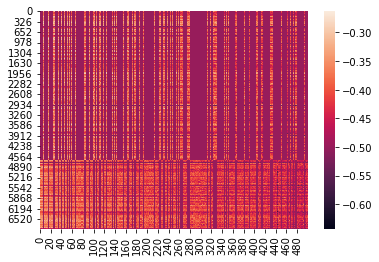

In [58]:
import seaborn as sns

sns.heatmap(check2_df.values)

## Plot heatmap of embedding

In [21]:
l = []

In [333]:
import seaborn as sns
import matplotlib.pyplot as plt

NameError: name 'test_peptides_repr_data_b' is not defined

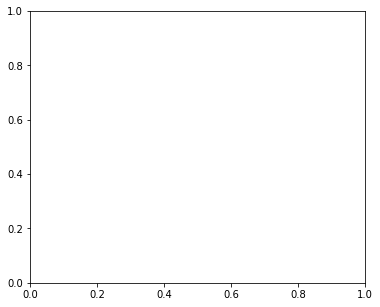

In [334]:
fig, ax = plt.subplots(nrows=1, ncols= 1, figsize=(6, 5))

representation = model.name

data = test_peptides_repr_data_b.drop(columns=["allele", "peptide"])
ax = sns.heatmap(data=data.values, ax=ax)
ax.set_title(f"{representation} representation")
plt.tight_layout

# Alleles motifs

In [62]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")


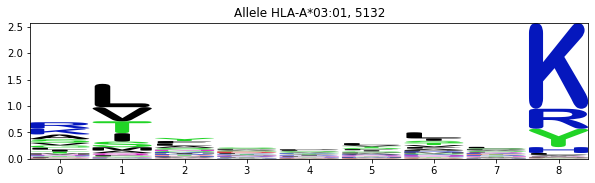

In [63]:
import logomaker
allele_name = 'HLA-A*03:01'
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][9]
make_logo_for_data(binders_array, allele_name)



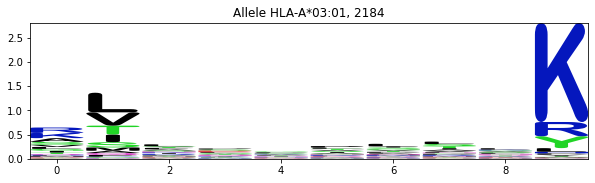

In [64]:
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][10]
matrix = logomaker.alignment_to_matrix(binders_array)
make_logo_for_data(binders_array, allele_name)


In [65]:
df = pd.DataFrame({'peptide': binders_array})
df['pre-last'] = df['peptide'].str[-2]
df['last'] = df['peptide'].str[-1]


In [66]:
df['last'].value_counts()

K    1606
R     230
Y     192
L      58
H      25
F      19
V      13
I      12
A       8
T       8
D       3
M       3
N       2
S       2
Q       1
E       1
P       1
Name: last, dtype: int64

In [67]:
df['pre-last'].value_counts()

L    288
K    165
G    156
A    149
S    146
P    137
F    133
N    132
Y    125
Q    116
T    104
V     99
R     97
E     97
I     57
H     50
D     47
M     45
W     26
C     15
Name: pre-last, dtype: int64

In [70]:
result_df = df[df['peptide'].str[-2] == 'R']

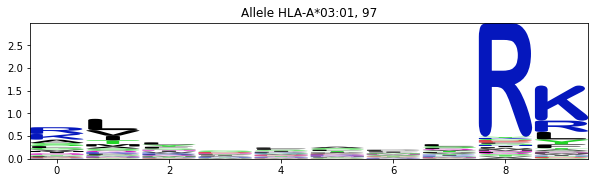

In [71]:
make_logo_for_data(result_df['peptide'].values, allele_name)


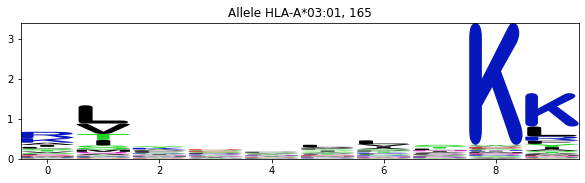

In [72]:
result_df = df[df['peptide'].str[-2] == 'K']
make_logo_for_data(result_df['peptide'].values, allele_name)


In [76]:
result_df = df[(df['peptide'].str[-2] == 'R') & (~df['peptide'].str[-1].isin(['R', 'K'])) ]

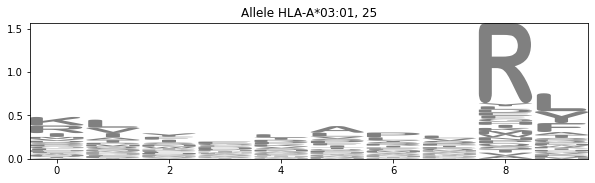

In [77]:
make_logo_for_data(result_df['peptide'].values, allele_name)


In [78]:
result_df = df[(df['peptide'].str[-2] == 'K') & (~df['peptide'].str[-1].isin(['R', 'K'])) ]

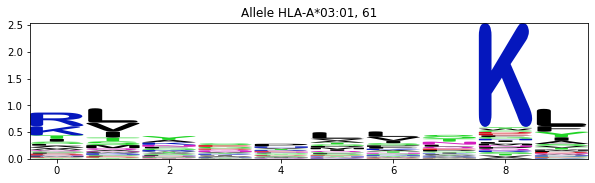

In [79]:
make_logo_for_data(result_df['peptide'].values, allele_name)


Text(0.5, 1.0, 'Allele HLA-A*01:01')

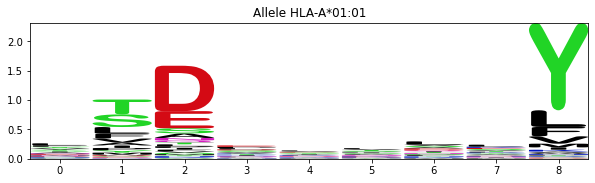

In [35]:
import logomaker
allele_name = 'HLA-A*01:01'
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][9]
matrix = logomaker.alignment_to_matrix(binders_array)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
ww_logo.ax.set_title(f"Allele {allele_name}")

# Some old analysis (just for history)

## Old embedding calculation

In [61]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

NameError: name 'selected_model_run' is not defined

In [13]:
model_bw = per_name_binding_model[mixed_model_bw]
model_bwv = per_name_binding_model[mixed_model_bwv]
model_v = per_name_binding_model[mixed_model_v]


In [17]:
%%time
print("Train")

train_peptides_repr_data_b_model_bw, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model_bw, set(train_peptides_b), paths_df=df_bw_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_bw['peptide'] = train_peptides_repr_data_b_model_bw.index.values
save_embeddingds(train_peptides_repr_data_b_model_bw, model_bw, 'train')

train_peptides_repr_data_b_model_bwv, _, _, _ = \
    get_model_representation(model_bwv, set(train_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_bwv['peptide'] = train_peptides_repr_data_b_model_bwv.index.values
save_embeddingds(train_peptides_repr_data_b_model_bwv, model_bwv, 'train')



train_peptides_repr_data_b_model_v,  _, _, _ = \
    get_model_representation(model_v, set(train_peptides_b), paths_df=df_v_paths, edge_value="log_probability", top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name
train_peptides_repr_data_b_model_v['peptide'] = train_peptides_repr_data_b_model_v.index.values
save_embeddingds(train_peptides_repr_data_b_model_v, model_v, 'train')


print("Test")
test_peptides_repr_data_b_model_bw,  _, _, _= \
    get_model_representation(model_bw, set(test_peptides_b), paths_df=df_bw_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name
test_peptides_repr_data_b_model_bw['peptide'] = test_peptides_repr_data_b_model_bw.index.values
save_embeddingds(test_peptides_repr_data_b_model_bw, model_bw, 'test')


test_peptides_repr_data_b_model_bwv,  _, _, _ = \
    get_model_representation(model_bwv, set(test_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name
test_peptides_repr_data_b_model_bwv['peptide'] = test_peptides_repr_data_b_model_bwv.index.values
save_embeddingds(test_peptides_repr_data_b_model_bwv, model_bwv, 'test')


test_peptides_repr_data_b_model_v,  _, _, _= \
    get_model_representation(model_v, set(test_peptides_b), paths_df=df_v_paths, edge_value="log_probability",  top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name    
test_peptides_repr_data_b_model_v['peptide'] = test_peptides_repr_data_b_model_v.index.values
save_embeddingds(test_peptides_repr_data_b_model_v, model_v, 'test')



per_name_representation_train["bw"] = {"db": train_peptides_repr_data_b_model_bw  }
per_name_representation_train["bwv"] = {"db": train_peptides_repr_data_b_model_bwv  }
per_name_representation_train["v"] = {"db": train_peptides_repr_data_b_model_v  }
per_name_representation_test["bw"] = {"db": test_peptides_repr_data_b_model_bw  }
per_name_representation_test["bwv"] = {"db": test_peptides_repr_data_b_model_bwv  }
per_name_representation_test["v"] = {"db": test_peptides_repr_data_b_model_v  }


Train
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 1533/1533 [01:40<00:00, 15.22it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 1593/1593 [01:55<00:00, 13.77it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 2000/2000 [02:21<00:00, 14.09it/s]


... (3 outputs left out)

100%|█████████████████████████████████████████████████████████████████████| 1593/1593 [00:28<00:00, 55.95it/s]


Finished
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|█████████████████████████████████████████████████████████████████████| 2000/2000 [00:38<00:00, 51.39it/s]


Finished
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Wall time: 9min 52s


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

## Heatmap

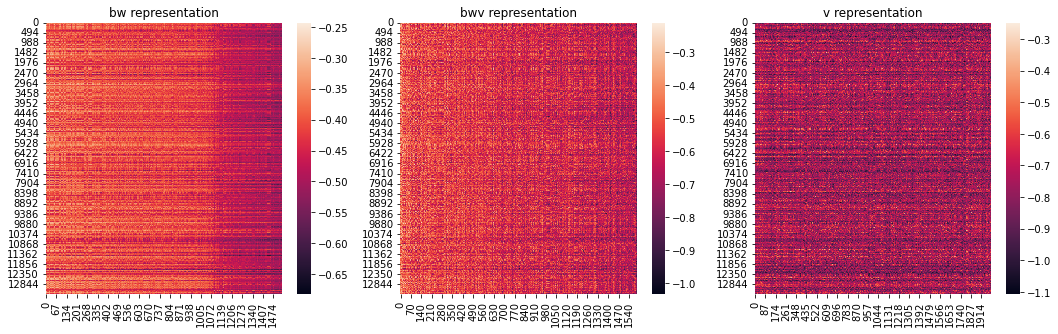

In [19]:
fig, axes = plt.subplots(nrows=1, ncols= 3, figsize=(18, 5))

representations= ['bw', 'bwv', 'v']

for i,representation in enumerate(representations):
    data = per_name_representation_train[representation]['db'].drop(columns=["allele", "peptide"])
    ax = sns.heatmap(data=data.values, ax=axes[i])
    ax.set_title(f"{representation} representation")
    plt.tight_layout



In [ ]:
df_v_paths

In [ ]:
data.describe()

,0,1,2,3,4,5,6,7,8,9,...,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
count,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,...,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000,19873.000000
mean,-1.067070,-1.058302,-1.065228,-1.050695,-1.064849,-1.059642,-1.085568,-1.063796,-1.074783,-1.072680,...,-1.060848,-1.077650,-1.077042,-1.023197,-1.076935,-1.095326,-1.092772,-1.134132,-1.070400,-1.084842
std,0.171402,0.182489,0.180374,0.171565,0.167488,0.176177,0.172055,0.179105,0.178771,0.172112,...,0.166851,0.167418,0.168829,0.172461,0.172579,0.173150,0.166933,0.154954,0.166417,0.167511
min,-1.446166,-1.444599,-1.444119,-1.452129,-1.446139,-1.442628,-1.452834,-1.446566,-1.456492,-1.447897,...,-1.529080,-1.454239,-1.460754,-1.527722,-1.462702,-1.451177,-1.452313,-1.457219,-1.529956,-1.460165
25%,-1.190884,-1.190428,-1.191343,-1.184345,-1.190542,-1.190154,-1.201886,-1.192240,-1.202450,-1.193571,...,-1.168371,-1.200345,-1.206049,-1.152281,-1.205022,-1.208356,-1.208730,-1.241343,-1.179316,-1.207329
50%,-1.072764,-1.066179,-1.068204,-1.060093,-1.069055,-1.070125,-1.083172,-1.068235,-1.079435,-1.076180,...,-1.052371,-1.080604,-1.085074,-1.032875,-1.082720,-1.092043,-1.095000,-1.139945,-1.066710,-1.087174
75%,-0.948327,-0.936270,-0.938280,-0.937860,-0.948465,-0.943987,-0.957934,-0.939732,-0.948956,-0.955498,...,-0.936163,-0.959323,-0.963852,-0.913754,-0.960770,-0.966146,-0.974065,-1.033306,-0.952474,-0.966990
max,-0.383194,-0.291527,-0.360350,-0.405895,-0.377822,-0.335044,-0.411205,-0.401107,-0.351187,-0.254972,...,-0.336242,-0.426618,-0.418639,-0.402584,-0.356660,-0.431028,-0.381794,-0.475942,-0.468970,-0.371424


## Count Peptides per paths (Not valid for non-sparse data)

In [35]:
df = per_name_representation_train["v"]["db"]
max([len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

20

<AxesSubplot:>

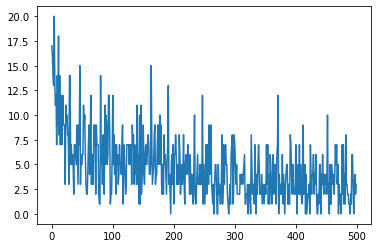

In [36]:
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

<AxesSubplot:>

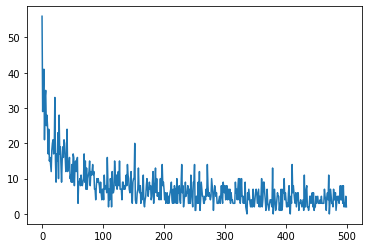

In [37]:
df = per_name_representation_train["bwv"]["db"]
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])


## Plot motifs for top paths

In [77]:
import logomaker
import matplotlib.pyplot as plt
from collections import defaultdict
from mhcgnomes import parse

def check_path_motif(top_paths, representation, length=9, start = 0, threshold=-0.4):
    fig,axes = plt.subplots(figsize=(5*top_paths, 3), nrows=2, ncols=top_paths)
    df = representation[representation.index.str.len() == length]
    for i in range(start, top_paths+start):
        print(i, end=" ")
        filtered_df = df[df[i] > threshold].copy()
        filtered_df['allele'] = filtered_df['allele'].apply(lambda x: parse(x).compact_string())
        counts = defaultdict(int)
        counts.update(dict(filtered_df['allele'].value_counts()))
        # print(counts)
        # print(filtered_df['allele'].value_counts())
        binders_array = filtered_df.index.values
        matrix = logomaker.alignment_to_matrix(binders_array)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[0, i-start])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        compact_alleles = [parse(allele).compact_string() for allele, cnt in sorted(counts.items())]
        counts_list = [i for allele, i in sorted(counts.items())]
        ww_logo.ax.set_title(f"Path {i}, \n {compact_alleles} \n {counts_list}")
        # filtered_df = filtered_df.sort_values(by=path_index)
        filtered_df = filtered_df.sort_values(by='allele')
        sns.boxplot(data=filtered_df, y=filtered_df[i], x='allele', ax=axes[1, i-start])

    print()



0 1 2 3 4 


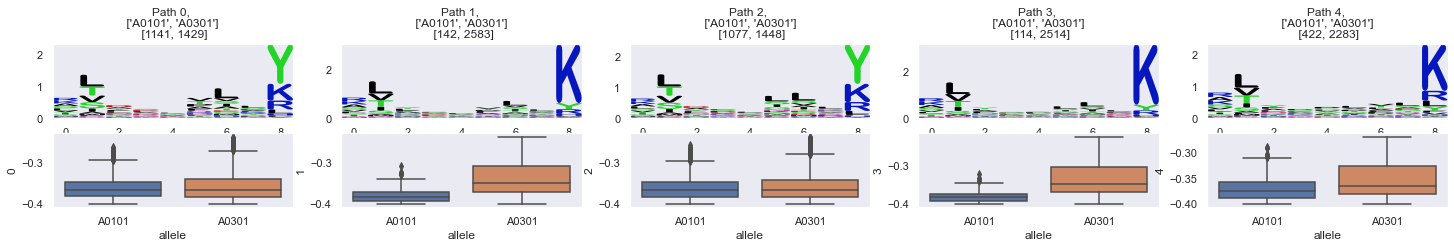

In [78]:
check_path_motif(5, per_name_representation_train["bwv"]["db"], start=0)


0 1 2 3 4 


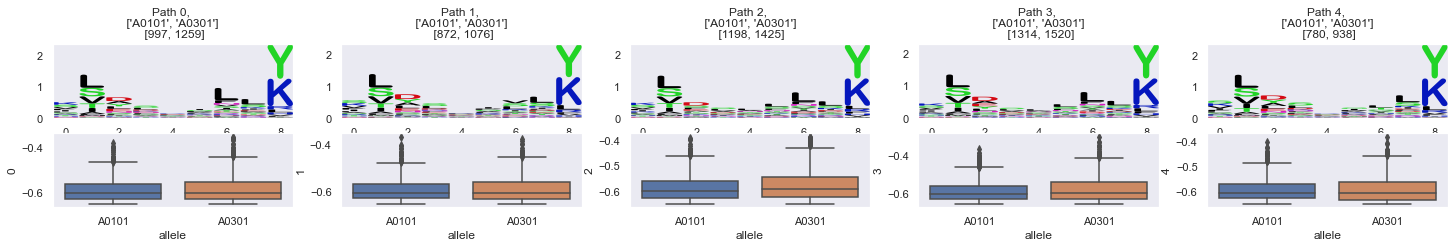

In [84]:
check_path_motif(5, per_name_representation_train["v"]["db"],start=0, threshold=-0.65)

In [87]:
per_name_representation_train["v"]["db"].loc[:,:10]

,0,1,2,3,4,5,6,7,8,9,10
FLNPLISKY,-0.583338,-0.499502,-0.647481,-0.575670,-0.584794,-0.573598,-0.669384,-0.516937,-0.680696,-0.668799,-0.565216
KSGPVIAKR,-0.758313,-0.760343,-0.763332,-0.832571,-0.759769,-0.710017,-0.844359,-0.775959,-0.758595,-0.677126,-0.766933
KSPSEPLIPK,-0.475953,-0.568151,-0.592640,-0.585523,-0.567576,-0.492600,-0.565322,-0.521948,-0.448726,-0.716066,-0.686409
NFLRSIAMLK,-0.734659,-0.736689,-0.892025,-0.808917,-0.736114,-0.743825,-0.820704,-0.713631,-0.808977,-0.640324,-0.895626
AYDPTAPTL,-0.857848,-0.859878,-0.918900,-0.917718,-0.859303,-0.820858,-0.929505,-0.781309,-0.932166,-0.637254,-0.922502
...,...,...,...,...,...,...,...,...,...,...,...
KVYPKAVER,-0.712731,-0.630197,-0.858706,-0.778535,-0.714186,-0.667054,-0.784389,-0.653712,-0.713013,-0.679135,-0.777744
RILLPIVQK,-0.626883,-0.544349,-0.810727,-0.727618,-0.628338,-0.642500,-0.712928,-0.591861,-0.591281,-0.722848,-0.729764
IPDQVIRVF,-0.795142,-0.719681,-0.855073,-0.853891,-0.793273,-0.781202,-0.881187,-0.767336,-0.862664,-0.811152,-0.781184
LVYIFEPEK,-0.801877,-0.803907,-0.820486,-0.740314,-0.803333,-0.807437,-0.810405,-0.742859,-0.766275,-0.629544,-0.824087


0 1 2 3 4 


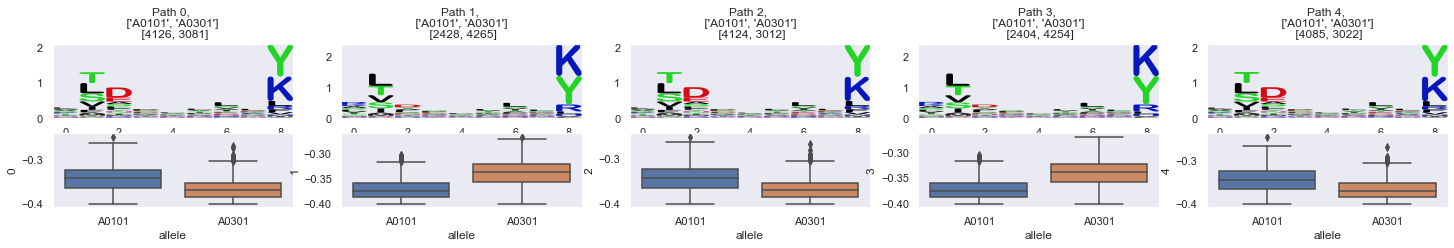

In [83]:
check_path_motif(5, per_name_representation_train["bw"]["db"])

## Compare paths

In [38]:
df = per_name_representation_train["v"]["db"]

In [39]:
from collections import defaultdict
from tqdm import tqdm
per_allele_per_path_cnt = dict()
observed_peptides = set()
paths_cnt = len(df.columns) - 1
for allele_name in selected_alleles:
    per_allele_per_path_cnt[allele_name] = defaultdict(int)
    for path_index in tqdm(range(paths_cnt)):
        filtered_df = df.loc[(df[path_index] != -55) & (df['allele'] == allele_name)]
        for peptide in filtered_df.index:
            if peptide not in observed_peptides:
                per_allele_per_path_cnt[allele_name][path_index] += 1
                observed_peptides.add(peptide)


100%|██████████| 500/500 [00:00<00:00, 661.37it/s]


## Compare peptides per paths for alleles (Not valid for non-sparse data)

In [40]:
from mhcgnomes import parse
cnt_df = pd.DataFrame(index=np.arange(paths_cnt))


for allele_name in selected_alleles:
    allele_counts = np.zeros(shape=(paths_cnt))
    for path_index in range(paths_cnt):
        allele_counts[path_index] = per_allele_per_path_cnt[allele_name][path_index]
    cnt_df[f'allele_{parse(allele_name).compact_string()}_cnt'] =  allele_counts

<AxesSubplot:xlabel='paths', ylabel='cnt of new peptides'>

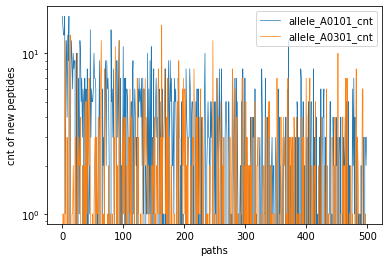

In [41]:
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.plot(ax= ax, xlabel='paths', ylabel='cnt of new peptides', lw=0.7, alpha=1, logy=True)


<AxesSubplot:xlabel='paths', ylabel='cumulative summ of peptides'>

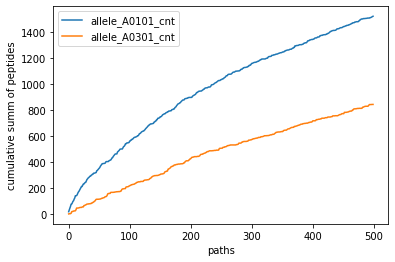

In [42]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.cumsum().plot(ax= ax, xlabel='paths', ylabel='cumulative summ of peptides',)

In [233]:
cnt_df.cumsum().loc[7500]

allele_A0101_cnt    4445.0
allele_A0301_cnt    3742.0
Name: 7500, dtype: float64

<AxesSubplot:>

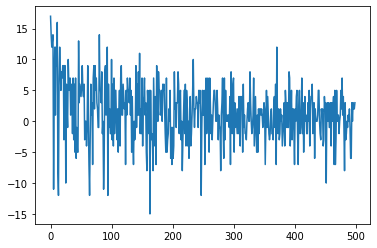

In [43]:
(cnt_df['allele_A0101_cnt'] - cnt_df['allele_A0301_cnt']).plot()

In [45]:
from collections import defaultdict

per_allele_path_counts = dict()
for allele_name in selected_alleles:
    per_allele_path_counts[allele_name] = defaultdict(int)

paths_cnt = len(df.columns) - 1
for path_index in range(paths_cnt):
    counts = df[df[path_index] != -55]['allele'].value_counts()
    for allele_name in selected_alleles:
        if allele_name in counts and counts[allele_name] != 0:
            per_allele_path_counts[allele_name][path_index] = counts[allele_name]

In [46]:
max(per_allele_path_counts[ALLELES[0]].values())

17

## How many peptides we represent with selected TOP

In [47]:
df.loc[(df.drop(columns=['allele']) != -55).any(axis=1)]['allele'].value_counts().sort_values()

HLA-A*03:01     843
HLA-A*01:01    1522
Name: allele, dtype: int64

In [151]:
selected_alleles

['HLA-A*01:01', 'HLA-A*03:01']

In [152]:
path_indexes = [i for i in range(paths_cnt)]
per_allele_df = dict()
for allele_name in selected_alleles:
    allele_cnt = [per_allele_path_counts[allele_name][i] if i in per_allele_path_counts[allele_name] else 0 for i in path_indexes]
    allele_df = pd.DataFrame({"path": path_indexes, "cnt": allele_cnt, "allele": allele_name})
    per_allele_df[allele_name] = allele_df

for allele_name in selected_alleles:
    per_allele_df[allele_name]['diff'] = per_allele_df[selected_alleles[1]]['cnt'] - per_allele_df[selected_alleles[0]]['cnt']

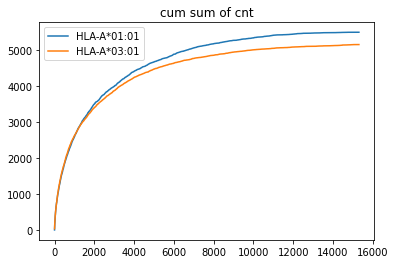

In [153]:


for allele_name in selected_alleles:
    per_allele_df[allele_name]['cnt'].cumsum().plot(ax= ax, x='path', title="cum sum of cnt", legend=True)
ax.legend(selected_alleles);

allele
HLA-A*03:01    4522
HLA-A*01:01    4720
Name: cnt, dtype: int64


<AxesSubplot:xlabel='path', ylabel='cnt'>

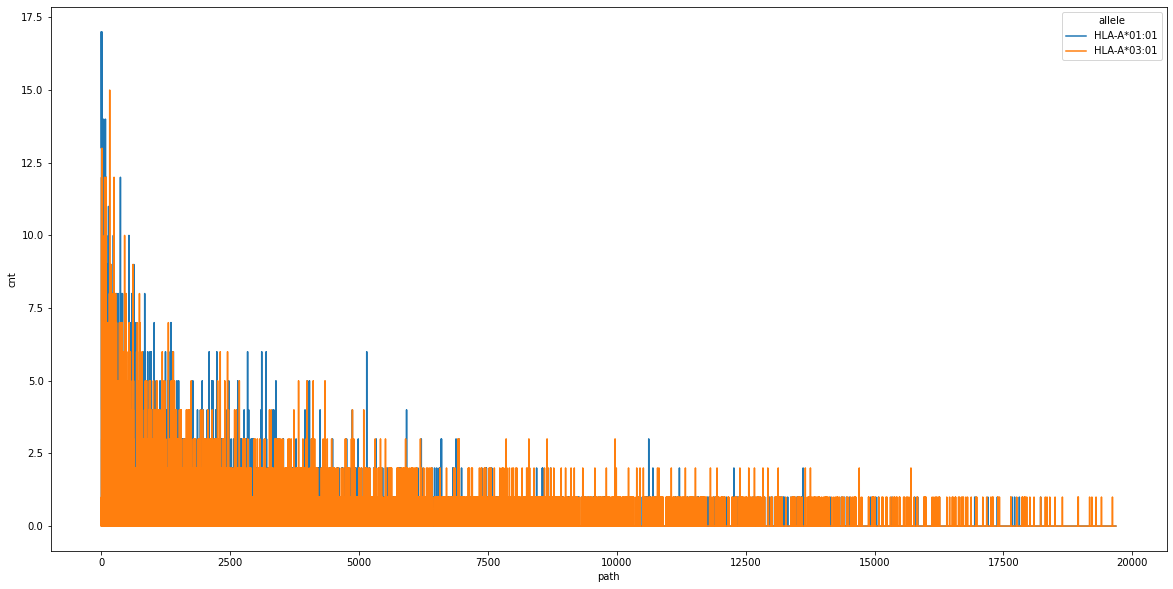

In [143]:

# sns.set_color_codes("pastel")
plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True)
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True)
print(df_to_plot.groupby('allele').sum()['cnt'].sort_values())

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')

In [237]:
for allele_name in selected_alleles:

    per_allele_df[allele_name] =  per_allele_df[allele_name].sort_values(by='diff').reset_index(drop=True)

    per_allele_df[allele_name]['prev_path'] = per_allele_df[allele_name]['path'].values
    per_allele_df[allele_name]['path'] = per_allele_df[allele_name].index.values



[]

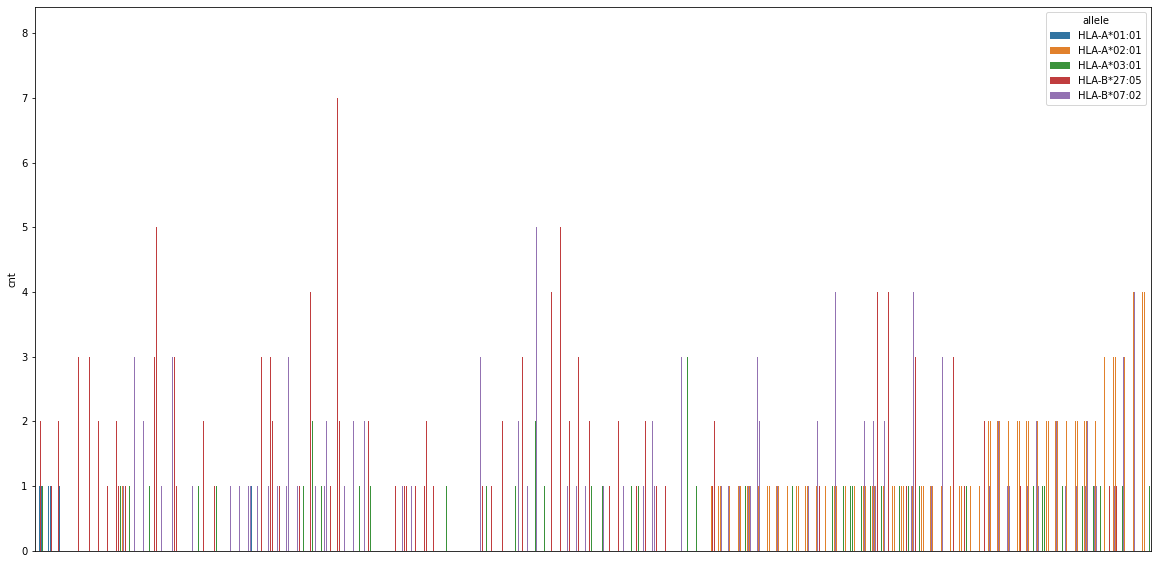

In [238]:

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True).sort_values(by='diff')
ax = sns.barplot(data=df_to_plot, x='path', y='cnt', hue='allele')
ax.set_xlabel('')
ax.set_xticks([])

<AxesSubplot:xlabel='path', ylabel='cnt'>

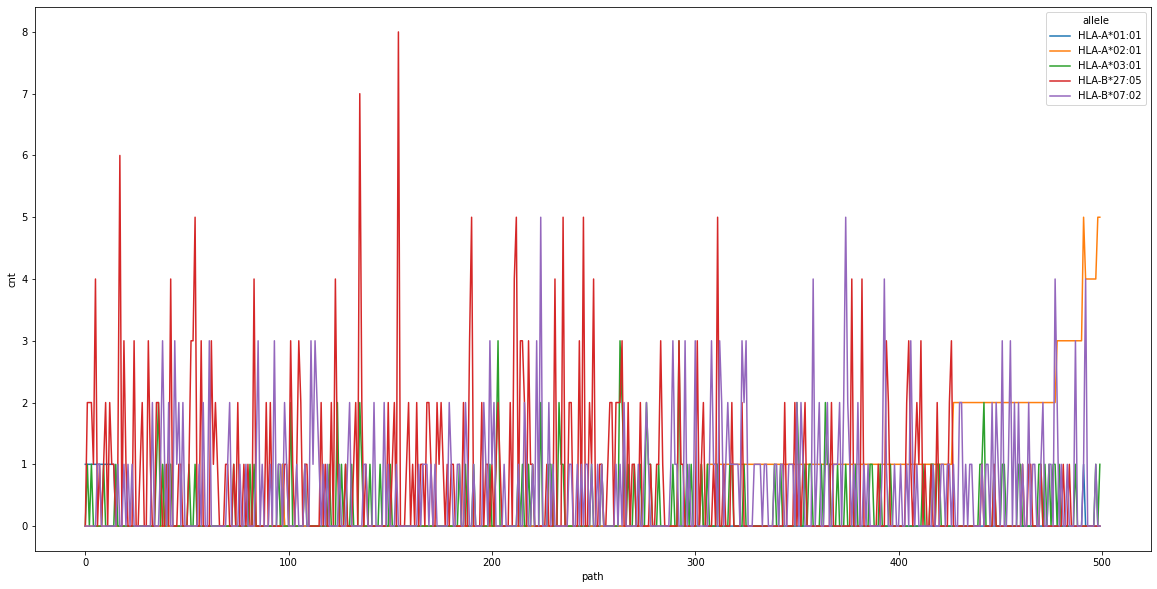

In [239]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')



In [36]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,label
PVSMTYLYNK,-0.767756,-1.088749,-1.088269,-1.136451,-1.110482,-1.126951,-0.866452,-0.985360,-0.735749,-0.874844,...,-1.145076,-1.230186,-1.147024,-0.874245,-1.095748,-1.457219,-1.120143,-1.239554,HLA-A*03:01,1
NYDLALKYF,-1.133209,-0.807913,-0.938645,-0.989824,-1.055381,-0.980324,-1.221345,-1.072828,-1.225003,-1.003204,...,-0.936420,-0.907656,-1.070104,-1.219688,-1.100022,-1.130287,-1.023211,-1.052718,HLA-A*01:01,0
TLKSFTVEK,-1.045980,-1.164910,-1.164430,-1.309880,-1.180526,-1.442628,-1.052648,-1.166878,-1.043307,-1.047711,...,-1.336272,-1.034953,-1.058531,-1.171488,-1.067980,-1.081329,-1.393245,-1.207510,HLA-A*03:01,1
AIFTDASTV,-1.062561,-0.941709,-0.941229,-0.655181,-0.822113,-0.645681,-1.069229,-1.062961,-1.006282,-0.945006,...,-0.834980,-0.810637,-0.835843,-0.821074,-0.946041,-1.074098,-0.576180,-0.962399,HLA-A*02:01,2
KLEYLAPSY,-1.049917,-0.929065,-0.928585,-0.919620,-0.980604,-1.052369,-0.925646,-1.050318,-1.060243,-0.932363,...,-1.184716,-0.893841,-0.919782,-1.054928,-1.011185,-1.143730,-1.156217,-1.098082,HLA-A*01:01,0
